# Session 10: The Training Loop

The Session 10 assignment on the same 20.5M-parameter model and FineWeb-Edu data as Session 9.

| Task | Section | What it checks |
|---|---|---|
| 1 | shapes | every tensor in one optimiser step, and what each dimension means |
| 2 | gradcheck | nudge one weight and compare with `backward()` |
| 3 | accum | correct vs average-of-averages gradient accumulation |
| 4 | gradnorm | grad norm every step: does it move before the loss? |
| 5 | mfu | Model FLOPs Utilisation and where the time goes |
| 6 | formats | 0.1 in fp32, bf16 and fp8 E4M3, bit by bit |

Code: `train/loop.py` (reusable training step) and `experiments/session10.py`. Total run time is about 12-15 minutes, most of it in step 2.

## 0. Setup

Open this notebook from the `mini_llm` folder and select the project's `.venv` as the kernel. The data in `data/prepared/` from Session 9 is reused.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

ROOT = Path.cwd()
assert (ROOT / 'config.py').exists(), 'Open this notebook from the mini_llm folder (next to config.py).'
LOG_DIR = ROOT / 'runs' / 'notebook'
LOG_DIR.mkdir(parents=True, exist_ok=True)
ENV = {**os.environ, 'PYTHONIOENCODING': 'utf-8', 'PYTHONUNBUFFERED': '1', 'TQDM_DISABLE': '1'}


def run(cmd, log_name):
    '''Run python <cmd> with this notebook kernel, stream the output, save a copy to runs/notebook/.'''
    print('$ python ' + cmd)
    print()
    args = [sys.executable] + cmd.split()
    with open(LOG_DIR / log_name, 'w', encoding='utf-8') as log, subprocess.Popen(
            args, cwd=ROOT, env=ENV, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, encoding='utf-8', errors='replace') as proc:
        for line in proc.stdout:
            print(line, end='')
            log.write(line)
    if proc.returncode != 0:
        raise RuntimeError(f'{cmd} failed with exit code {proc.returncode}')
    print(f'[saved runs/notebook/{log_name}]')


print('Python :', sys.executable)
print('Project:', ROOT)

Python : c:\Users\ajair\Projects\ERA_V5\mini_llm\.venv\Scripts\python.exe
Project: c:\Users\ajair\Projects\ERA_V5\mini_llm


## 1. Checks, no training (Tasks 1, 2, 6), about 1 minute

In [2]:
run('-m experiments.session10 --section checks', '10_checks.txt')

$ python -m experiments.session10 --section checks

device cuda, model D=384 L=8 H=6 T=256 V=8192, <pad>=0 <eos>=1

1. SHAPES: every tensor in one optimiser step (Task 1)
  one step = 4 micro-batches x 8 sequences x 256 tokens = 32 sequences seen by the optimiser

  tensor                    shape                 dtype     meaning
  --------------------------------------------------------------------------------------------------
  tokens (micro-batch 1)    [8, 256]              int64     B sequences x T token ids
  targets (shifted, masked) [8, 255]              int64     B x (T-1): next token, -100 where masked
  rope cos / sin            [256, 64]             float32   T x hd: one rotation angle per position, per pair
  tok_emb(tokens)           [8, 256, 384]         float32   one D-vector per token: B x T x D
  block 1 attn_norm         [8, 256, 384]         float32   RMSNorm keeps the shape, rescales each token vector
  q_proj output             [8, 256, 384]         bfloat16  que

## 2. Training runs (Tasks 3, 4), about 8-10 minutes

Two 600-step runs that differ only in how micro-batch losses are combined, then a learning-rate range test with clipping off.

In [3]:
run('-m experiments.session10 --section train', '11_train.txt')

$ python -m experiments.session10 --section train

device cuda, model D=384 L=8 H=6 T=256 V=8192, <pad>=0 <eos>=1

4. GRADIENT ACCUMULATION: correct vs average of averages (Task 3)
  4 micro-batches of 8 rows; rows in micro-batch i keep [256, 128, 64, 32] real tokens, the rest is <pad>

  4a. One step's gradient, compared with ONE big batch holding the same rows (fp32):

    different lengths: real targets per micro-batch [2038, 1016, 504, 248]
    share of tokens  ['53.5%', '26.7%', '13.2%', '6.5%']   vs the bug's vote ['25.0%', '25.0%', '25.0%', '25.0%']
    method                         loss  grad rel. error    cosine
    one big batch (reference)    9.0773                -         -
    token-weighted (correct)     9.0773         1.22e-06  1.000000
    average of averages          9.0817         5.80e-01  0.828221

    equal lengths: real targets per micro-batch [2038, 2039, 2040, 2038]
    method                         loss  grad rel. error    cosine
    one big batch (reference

run,bug,correct
step,,
0,9.0895,9.0895
50,7.2062,7.1449
100,6.7076,6.5746
150,6.4320,6.3001
200,6.2883,6.1301
250,6.1590,5.9932
300,6.0603,5.8703
350,5.9838,5.7768
400,5.9010,5.6886


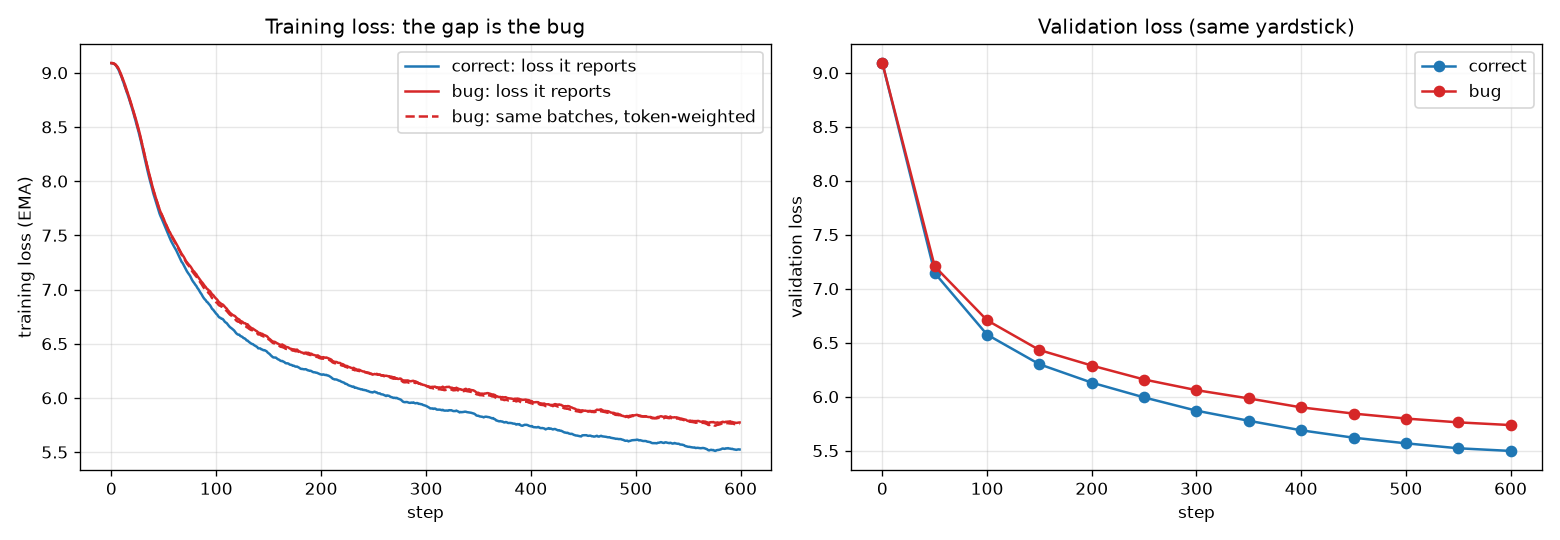

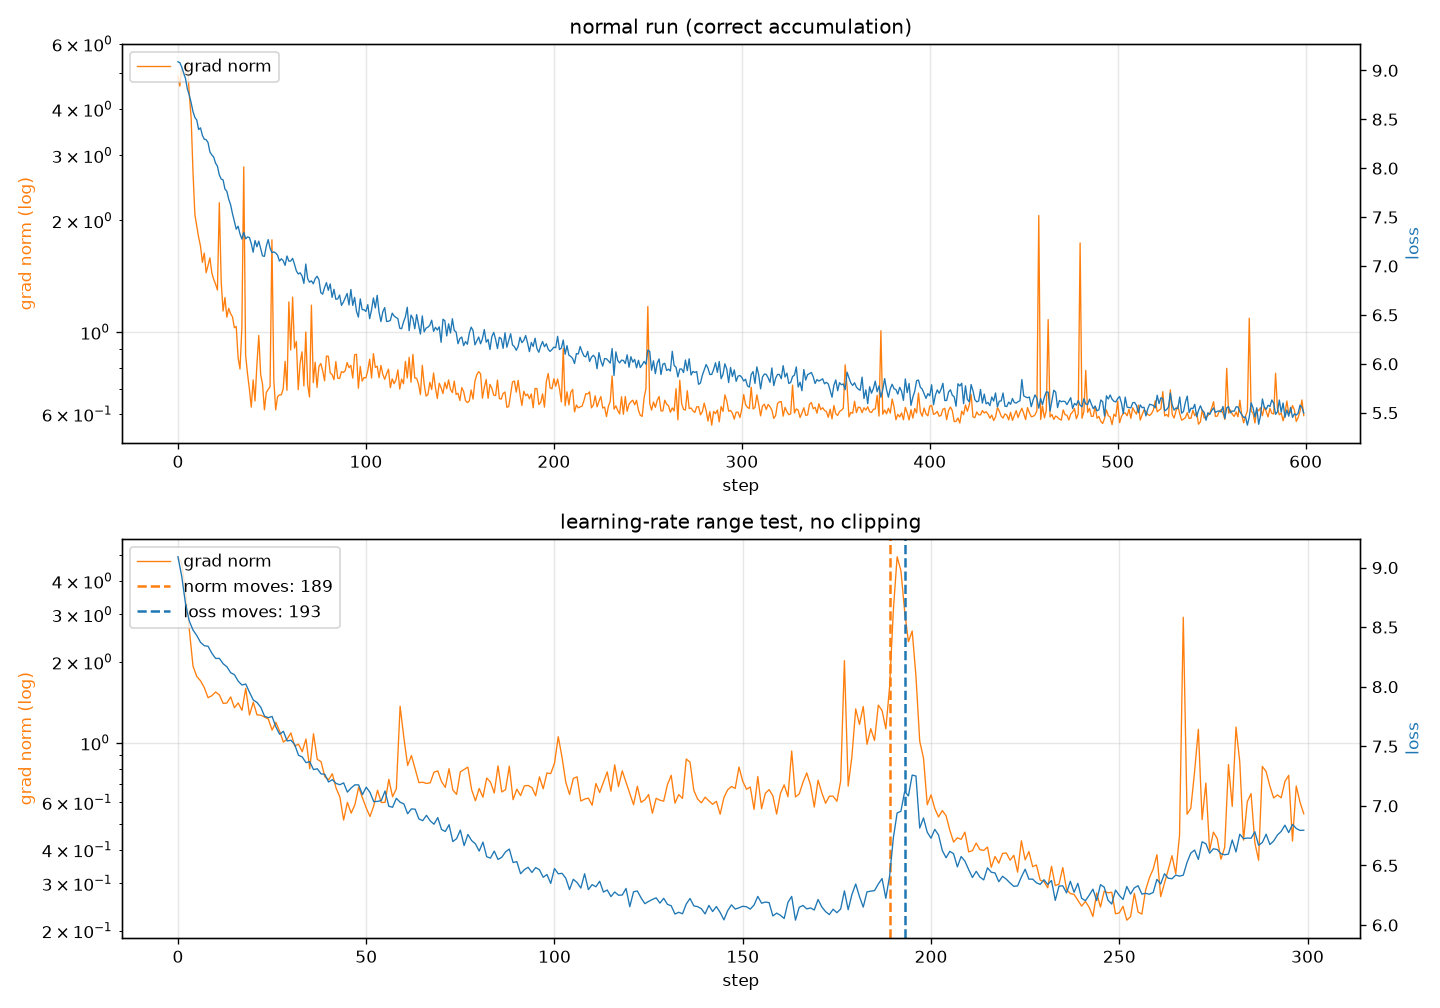

In [4]:
import pandas as pd
from IPython.display import Image, display

log = pd.read_csv(ROOT / 'runs' / 'session10' / 'train_log.csv')
steps = log.dropna(subset=['val_loss'])
display(steps.pivot(index='step', columns='run', values='val_loss').round(4))
for png in ('accumulation.png', 'gradnorm.png'):
    path = ROOT / 'runs' / 'session10' / png
    if path.exists():
        display(Image(filename=str(path)))

## 3. MFU (Task 5), about 2-3 minutes

To also compare against the spec sheet, add `--spec-tflops X` with your GPU's dense bf16 TFLOP/s.

In [5]:
run('-m experiments.session10 --section mfu', '12_mfu.txt')

$ python -m experiments.session10 --section mfu

device cuda, model D=384 L=8 H=6 T=256 V=8192, <pad>=0 <eos>=1

6. MFU: how much of the GPU are we using? (Task 5)
  GPU: NVIDIA GeForce RTX 5060 Laptop GPU, 26 SMs, 8.0 GiB
  nvidia-smi (power limit, max power limit, SM clock now, SM clock max): [N/A], 115.00 W, 120 MHz, 3090 MHz

  6a. What the GPU can actually do: bf16 matrix multiply, measured
     1024 x 1024     22.9 TFLOP/s
     2048 x 2048     30.7 TFLOP/s
     4096 x 4096     30.9 TFLOP/s
     8192 x 8192     29.5 TFLOP/s
    measured peak: 30.9 TFLOP/s   (pass --spec-tflops X to also report against the spec sheet)

  6b. FLOPs per token (forward + backward):
    notes' rule 6N, N = all 20,453,760 weights                122.7 MFLOP
    refined: 6 x 17,308,032 matmul weights + attention       113.3 MFLOP
    (the embedding is a lookup, not a multiply; attention scores add 12 x L x T x D)

  6c. Training throughput, 20 timed steps after 5 warm-up steps:
    configuration          

## 4. Results

The numbers and what they show are written up in [README.md](README.md).